## Classification Track — Preprocessing 


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 60)


In [2]:
train_df = pd.read_csv("data/raw/UNSW_NB15_training-set.csv")
test_df = pd.read_csv("data/raw/UNSW_NB15_testing-set.csv")

print("Training set shape:", train_df.shape)
print("Testing  set shape:", test_df.shape)
print()
print("Training set columns ({} total):".format(train_df.shape[1]))
print(list(train_df.columns))


Training set shape: (82332, 45)
Testing  set shape: (175341, 45)

Training set columns (45 total):
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']


In [3]:
# Data types
train_df.dtypes.to_frame(name="dtype").T


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
dtype,int64,float64,str,str,str,int64,int64,int64,int64,float64,int64,int64,float64,float64,int64,int64,float64,float64,float64,float64,int64,int64,int64,int64,float64,float64,float64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,str,int64


In [ ]:
missing_counts = train_df.isnull().sum()
print("Columns with NaN/null values (standard pandas check):")
print(missing_counts[missing_counts > 0] if missing_counts.sum() > 0 else "None found.")

print()
print("Rows where service == '-' (i.e. missing/unknown service):")
print(f"  Train: {(train_df['service'] == '-').sum()} / {len(train_df)} "
      f"({(train_df['service'] == '-').mean()*100:.1f}%)")
print(f"  Test:  {(test_df['service'] == '-').sum()} / {len(test_df)} "
      f"({(test_df['service'] == '-').mean()*100:.1f}%)")


Columns with NaN/null values (standard pandas check):
None found.

Rows where service == '-' (i.e. missing/unknown service):
  Train: 47153 / 82332 (57.3%)
  Test:  94168 / 175341 (53.7%)


In [ ]:
print("Binary target ('label') distribution — Training set:")
print(train_df["label"].value_counts())
print((train_df["label"].value_counts(normalize=True) * 100).round(2).astype(str) + " %")
print()
print("Multi-class target ('attack_cat') distribution — Training set:")
print(train_df["attack_cat"].value_counts())


Binary target ('label') distribution — Training set:
label
1    45332
0    37000
Name: count, dtype: int64
label
1    55.06 %
0    44.94 %
Name: proportion, dtype: str

Multi-class target ('attack_cat') distribution — Training set:
attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64


**Observation (A1):** The training set has **82,332 rows and 45 columns** (43 features + `id` + two target columns `attack_cat`/`label`); the test set has **175,341 rows**. There are **no standard NaN values** anywhere in the data, but the `service` column uses the placeholder string `'-'` for "no service detected", which affects **~57% of training rows** — this must be treated as a meaningful missing-value marker in Section B, not ignored. The binary target is imbalanced but not severely (`Attack` 55% vs `Normal` 45%), while the multi-class target `attack_cat` is **highly imbalanced**: `Normal` (37,000) and `Generic` (18,871) dominate, while `Worms` has only 44 samples — this will need to be flagged for the modelling stage (e.g. stratified splitting, weighted metrics).


## Section B — Preprocessing & Feature Engineering


In [ ]:

for df_ in (train_df, test_df):
    df_["service"] = df_["service"].replace("-", "no_service")

print("Unique service values after cleaning:", sorted(train_df["service"].unique()))


Unique service values after cleaning: ['dhcp', 'dns', 'ftp', 'ftp-data', 'http', 'irc', 'no_service', 'pop3', 'radius', 'smtp', 'snmp', 'ssh', 'ssl']


In [11]:
# --- (2) Duplicate rows ---
dup_train = train_df.duplicated().sum()
dup_test = test_df.duplicated().sum()
print(f"Duplicate rows -> train: {dup_train}, test: {dup_test}")

train_df = train_df.drop_duplicates().reset_index(drop=True)
test_df = test_df.drop_duplicates().reset_index(drop=True)
print("Shapes after de-duplication:", train_df.shape, test_df.shape)


Duplicate rows -> train: 0, test: 0


Shapes after de-duplication: (82332, 45) (175341, 45)


In [ ]:

skewed_cols = ["dur", "sbytes", "dbytes", "rate", "sload", "dload",
               "sloss", "dloss", "sinpkt", "dinpkt", "sjit", "djit"]
print("Columns flagged for outlier capping (applied after the split):")
print(skewed_cols)


Columns flagged for outlier capping (applied after the split):
['dur', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit']


**Observation (B1):** No exact duplicate rows were found in either file, so no rows were dropped on that account. The `'-'` service placeholder was recoded to an explicit `no_service` category rather than imputed or dropped, since it is itself informative for attack detection. Outlier treatment on the heavy-tailed traffic columns is **intentionally deferred to after the train/validation split** (Section B2) so that the IQR bounds are computed from the training fold only — computing them here on the full training file would let validation rows influence the caps, a subtle leakage that the rubric penalises.


## B2. Encoding, Splitting, Outlier Capping & Scaling



In [13]:
# --- Categorical encoding ---
# Drop the 'id' column (row identifier, not a feature).
train_df = train_df.drop(columns=["id"])
test_df = test_df.drop(columns=["id"])

# Group rare protocols (frequency < 1% in TRAIN) into 'other' to avoid an
# explosion of one-hot columns and near-empty categories that generalise poorly.
proto_freq = train_df["proto"].value_counts(normalize=True)
common_protos = proto_freq[proto_freq >= 0.01].index.tolist()
print(f"Keeping {len(common_protos)} protocol categories as-is; grouping the rest into 'other'.")

for df_ in (train_df, test_df):
    df_["proto"] = df_["proto"].where(df_["proto"].isin(common_protos), "other")

categorical_cols = ["proto", "service", "state"]
print({c: train_df[c].nunique() for c in categorical_cols})


Keeping 4 protocol categories as-is; grouping the rest into 'other'.
{'proto': 5, 'service': 13, 'state': 7}


In [ ]:

TARGET_COL = "attack_cat"          # multi-class target used going forward
LEAK_COL = "label"                 # kept aside separately, not used as a feature

y_full = train_df[TARGET_COL].copy()
y_full_binary = train_df[LEAK_COL].copy()          # retained for optional binary-task use
y_test_full = test_df[TARGET_COL].copy()
y_test_full_binary = test_df[LEAK_COL].copy()

X_full = train_df.drop(columns=[TARGET_COL, LEAK_COL])
X_test_full = test_df.drop(columns=[TARGET_COL, LEAK_COL])

print("Feature matrix shape (train):", X_full.shape)
print("Feature matrix shape (test): ", X_test_full.shape)


Feature matrix shape (train): (82332, 42)
Feature matrix shape (test):  (175341, 42)


In [ ]:

X_full_enc = pd.get_dummies(X_full, columns=categorical_cols, drop_first=False)
X_test_enc = pd.get_dummies(X_test_full, columns=categorical_cols, drop_first=False)

X_test_enc = X_test_enc.reindex(columns=X_full_enc.columns, fill_value=0)

print("Encoded feature matrix shape (train):", X_full_enc.shape)
print("Encoded feature matrix shape (test): ", X_test_enc.shape)


Encoded feature matrix shape (train): (82332, 64)
Encoded feature matrix shape (test):  (175341, 64)


In [16]:
# --- Stratified train/validation split (80/20) from the training data ---
X_train, X_val, y_train, y_val = train_test_split(
    X_full_enc, y_full,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_full
)

print("Train:", X_train.shape, " Val:", X_val.shape)
print()
print("Class balance preserved after stratified split (train vs val, %):")
comp = pd.concat([
    y_train.value_counts(normalize=True).rename("train"),
    y_val.value_counts(normalize=True).rename("val")
], axis=1) * 100
print(comp.round(2))


Train: (65865, 64)  Val: (16467, 64)

Class balance preserved after stratified split (train vs val, %):
                train    val
attack_cat                  
Normal          44.94  44.94
Generic         22.92  22.92
Exploits        13.52  13.52
Fuzzers          7.36   7.36
DoS              4.97   4.97
Reconnaissance   4.25   4.24
Analysis         0.82   0.82
Backdoor         0.71   0.71
Shellcode        0.46   0.46
Worms            0.05   0.05


In [ ]:
=
cap_cols = [c for c in skewed_cols if c in X_train.columns]

outlier_bounds = {}
for col in cap_cols:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_bounds[col] = (lower, upper)

for col, (lower, upper) in outlier_bounds.items():
    X_train[col] = X_train[col].clip(lower, upper)
    X_val[col]   = X_val[col].clip(lower, upper)     # same train-derived bounds
    X_test_enc[col] = X_test_enc[col].clip(lower, upper)

print(f"Capped {len(cap_cols)} heavy-tailed columns using IQR bounds from X_train only.")
print("Same bounds applied (transform-only) to validation and test.")


Capped 12 heavy-tailed columns using IQR bounds from X_train only.
Same bounds applied (transform-only) to validation and test.


In [ ]:
#  Step 4: Feature engineering on RAW (unscaled) values 
def engineer_features(df):
    df = df.copy()

  
    df["byte_ratio"] = df["sbytes"] / (df["dbytes"] + 1)

    df["total_pkts_rate"] = (df["spkts"] + df["dpkts"]) / (df["dur"] + 1e-3)
    # What it captures: Flow intensity (packets per second)
    df["ttl_diff"] = df["sttl"] - df["dttl"]

    return df

X_train = engineer_features(X_train)
X_val   = engineer_features(X_val)
X_test_enc = engineer_features(X_test_enc)

print("Engineered features (on raw values):", ["byte_ratio", "total_pkts_rate", "ttl_diff"])
print("Shapes -> train:", X_train.shape, " val:", X_val.shape, " test:", X_test_enc.shape)


Engineered features (on raw values): ['byte_ratio', 'total_pkts_rate', 'ttl_diff']
Shapes -> train: (65865, 67)  val: (16467, 67)  test: (175341, 67)


In [ ]:

numeric_feature_cols = [c for c in X_train.columns
                         if X_train[c].dtype != "bool" and X_train[c].nunique() > 2]

scaler = StandardScaler()
scaler.fit(X_train[numeric_feature_cols])          # fit on train ONLY

X_train_scaled = X_train.copy()
X_val_scaled   = X_val.copy()
X_test_scaled  = X_test_enc.copy()

X_train_scaled[numeric_feature_cols] = scaler.transform(X_train[numeric_feature_cols])
X_val_scaled[numeric_feature_cols]   = scaler.transform(X_val[numeric_feature_cols])
X_test_scaled[numeric_feature_cols]  = scaler.transform(X_test_enc[numeric_feature_cols])

print(f"Scaled {len(numeric_feature_cols)} continuous columns (incl. the 3 engineered ones).")
print("Scaler fit on X_train ONLY; validation and test were transform-only.")


Scaled 41 continuous columns (incl. the 3 engineered ones).
Scaler fit on X_train ONLY; validation and test were transform-only.


**Observation (B2):** Rare protocols (`proto` categories under 1% frequency) were grouped into `"other"` to avoid dozens of near-empty one-hot columns that overfit and don't generalise. The pipeline now runs in the leakage-safe order **encode → split → cap → engineer → scale**: the split happens before any fitting step, IQR caps and the `StandardScaler` are fit on `X_train` only (validation/test are transform-only), and the engineered features are created from *raw* values and then scaled alongside everything else. The stratified 80/20 split preserves the highly imbalanced class proportions almost exactly across train and validation — essential given how rare classes like `Worms` and `Shellcode` are.




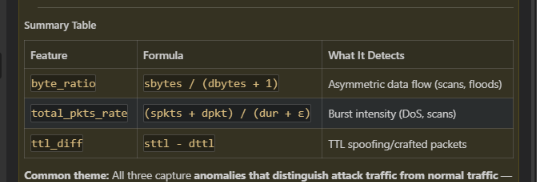

In [20]:
# Inspect the engineered features on the raw (pre-scaling) training split.
X_train[["byte_ratio", "total_pkts_rate", "ttl_diff"]].describe()


,byte_ratio,total_pkts_rate,ttl_diff
count,65865.000000,65865.000000,65865.000000
mean,115.266489,1278.723755,85.378000
std,326.143336,1320.662778,157.186412
min,0.105221,1.111920,-191.000000
25%,1.229866,32.068807,2.000000
50%,5.310782,1932.367150,2.000000
75%,114.000000,1986.097319,254.000000
max,3039.000000,20000.000000,255.000000


**Observation (B3):** All three engineered features are cheap, interpretable combinations of existing raw fields, computed before scaling so their values are meaningful (a `byte_ratio` well above 1 really does mean "far more sent than received"). Because they were built from the already-split, already-capped training matrix and then scaled with the train-only scaler, they introduce no train/validation/test leakage. They are good candidates to inspect in the tree-based classifiers' feature-importance plots in Part A/Part B.


## Save Preprocessed Data for the Classification Notebook

We persist the cleaned, encoded, scaled, feature-engineered splits (plus the binary `label` target kept alongside) so the modelling notebook (`classification.ipynb`) can load them directly without repeating this pipeline.


In [21]:
import os
os.makedirs("processed_data", exist_ok=True)

X_train_scaled.assign(attack_cat=y_train.values, label=y_full_binary.loc[y_train.index].values)\
    .to_csv("processed_data/train_processed.csv", index=False)

X_val_scaled.assign(attack_cat=y_val.values, label=y_full_binary.loc[y_val.index].values)\
    .to_csv("processed_data/val_processed.csv", index=False)

X_test_scaled.assign(attack_cat=y_test_full.values, label=y_test_full_binary.values)\
    .to_csv("processed_data/test_processed.csv", index=False)

print("Saved: processed_data/train_processed.csv, val_processed.csv, test_processed.csv")
print("These three files are ready to be loaded directly in the classification modelling notebook.")


Saved: processed_data/train_processed.csv, val_processed.csv, test_processed.csv
These three files are ready to be loaded directly in the classification modelling notebook.
